# 1.1 Array-Covariance Inversion

In this example, we will perform array-covariance inversion on synthetic data consisting of an abyssal T-phase signal and cylindrically-harmonic ambient noise.

In [1]:
#__ Import: Numerical __
import numpy as np

#__ Import: Topophone2 __
from topophone2.modelling import ArrayCovarianceModel
from topophone2.inversion import Uniform, Posterior, LinearFlowsModel, Inference
from topophone2.utils.read import read_txt

#__ Import: Plotting __
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmcrameri.cm as cmc

#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Set up: Random seed __
np.random.seed(2026)

#__ Set up: File paths __
data_dir  = '../data/TRIAD_15DB'
model_dir = '../models/TRIAD_15DB'

Hello from topophone2!


### 1.1.1 Read synthetic data

The synthetic data was generated using `pyat` with the following parameters:

In [2]:
#__ Read: Signal + noise __
out = read_txt(f"{data_dir}/TRIAD_FULL_15DB_topophone2.txt")
freq_Hz   = out[0]  # Frequency vector         [Hz]        (frequency)
x         = out[1]  # Receiver position        [m]         (receiver, direction)
Gamma_obs = out[2]  # Array-covariance matrix  [uPa2.Hz-1] (frequency, receiver, receiver)
N_obs     = out[3]  # Independent observations
freq      = 2 * np.pi * freq_Hz  # Angular frequency vector [rad.s-1] (frequency)

#__ Read: Noise only __
out = read_txt(f"{data_dir}/TRIAD_NOISE_15DB_topophone2.txt")
Gamma_obs_noise = out[2]  # Array-covariance matrix  [uPa2.Hz-1] (frequency, receiver, receiver)
N_obs_noise     = out[3]  # Independent observations

In [3]:
#__ (HIDE FROM GITHUB EXAMPLE) __

#__ Load synthetic parameters __
sim_data = np.load('../data/SYNTHETICS.npz')

#__ Unpack: Signal __
slowness_T = sim_data['slowness_T']  # Horizontal slowness    [s.m-1]     (source, mode, direction)
energy_T   = sim_data['energy_T']    # Recorded energy        [uPa2.Hz-1] (source, mode)
xS_T       = sim_data['xS_T']        # Source location        [m]         (source, direction)
w_energy   = sim_data['w_energy']    # Relative source energy [uPa2.Hz-1] (source)

#__ Unpack: Noise __
slowness_J = sim_data['slowness_J']  # Horizontal slowness    [s.m-1]     (source, direction)
energy_J   = sim_data['energy_J']    # Recorded energy        [uPa2.Hz-1] (source)
az_J       = sim_data['az']          # Source azimuth         [deg]       (source)
s0_J       = sim_data['s0'][0]       # Noise slowness         [s.m-1]

#__ Unpack: True model __
m_true = sim_data['m_true']

### 1.1.2 Set up forward model

The forward model is ...

In [4]:
#__ Noise apparent slowness [s.m-1] __
synthetics = np.load('../data/SYNTHETICS.npz')
s0_J       = synthetics['s0'][0]

#__ Signals present __
sigs = [
    'normal',                   # Gaussian density-function field
    dict(
        sig       = 'noise2D',  # Cylindrically-harmonic noise field
        s         = s0_J,       # Local apparent slowness [s.m-1]
        max_order = 1           # Maximum cylindrical-harmonic order
    )
]

#__ Forward modeller __
array_covariance_model = ArrayCovarianceModel(
    x = x,                  # Receiver locations       [m]       (receiver, direction)
    freq = freq,            # Angular frequency vector [rad.s-1] (frequency)
    sigs = sigs,            # Signals present
    calc_noise_only = True  # Calculate an additional noise-only array-covariance matrix
)

### 1.1.3 Set up the likelihood calculator

The prior pdf is... the model vector contains parameters...

In [5]:
#__ Prior bounds __
lower = np.array([                                 # Lower bound
    50.,  -5.0e-4, 8.0e-5, 1.0e-6, 1.0e-6, -0.99,  #     'normal' parameters
    50., -0.8, -0.8                                #     'noise2D' parameters
])
upper = np.array([                                 # Upper bound
    100., -4.2e-4, 1.6e-4, 5.0e-5, 5.0e-5,  0.99,  #     'normal' parameters
    100., 0.8,  0.8                                #     'noise2D parameters
])

#__ Uniform prior pdf __
prior = Uniform(lower=lower, upper=upper)

The posterior pdf is...

In [6]:
#__ Posterior pdf __
posterior = Posterior(
    Gamma_obs       = Gamma_obs,        # Observed array-covariance matrix
    N_obs           = N_obs,            # Number of independent observations
    Gamma_obs_noise = Gamma_obs_noise,  # Observed (noise-only) array-covariance matrix
    N_obs_noise     = N_obs_noise,      # Number of independent (noise-only) observations
    prior           = prior,            # Uniform prior pdf
    array_covariance_model = array_covariance_model  # Forward modeller
)

### 1.1.4 Set up the inversion

The Normalising flow model..

In [7]:
#__ Number of flows __
N_flow = 8

#__ Normalising flow model __
flow_model = LinearFlowsModel(
    N_param      = len(lower),      # Number of model parameters
    prior_bounds = (lower, upper),  # Uniform prior bounds
    N_flow       = N_flow           # Number of flows
)

The inversion class is...

In [8]:
#__ Inversion parameters __
learning_rate = 5e-4                       # Learning rate for the optimiser
N_iterations  = 30000                      # Number of iterations for optimiser
N_montecarlo  = 100                        # Number of samples to estimate ELBO

#__ Set up inverse problem __
inverse_problem = Inference(
    flow_model    = flow_model,     # Normalising flows model
    posterior     = posterior,      # Posterior pdf
    learning_rate = learning_rate,  # Learning rate
    outpath       = f"{model_dir}"  # Path to save results
)

### 1.1.5 Run the inversion

In [10]:
#__ Run inversion __
inverse_problem.invert(
    N_iterations = N_iterations,  # Number of iterations for optimiser
    N_montecarlo = N_montecarlo,  # Number of samples to estimate ELBO
    verbose      = True,          # Print progress
    N_out        = 6              # Number of print statements
)

#__ Save flows model for later use __
inverse_problem.save()

#__ Extract log-ELBO __
lnELBO = inverse_problem.get_lnELBO()

----------------------------------------

Iteration:     0,	Loss:   42777.36
The elapsed time is: 0.23 s
Iteration:  5000,	Loss:   13903.31
The elapsed time is: 100.16 s
Iteration: 10000,	Loss:   13851.91
The elapsed time is: 202.15 s
Iteration: 15000,	Loss:   13849.85
The elapsed time is: 298.58 s
Iteration: 20000,	Loss:   13849.83
The elapsed time is: 393.39 s
Iteration: 25000,	Loss:   13849.85
The elapsed time is: 490.11 s
Iteration: 30000,	Loss:   13849.78
The elapsed time is: 588.12 s
----------------------------------------

Finish training!


Statistics on the... sample the normalising flows models

In [11]:
#__ Number of samples to draw __
N_samples = 20000

#__ Draw model samples from posterior pdf __
m = inverse_problem.sample(N_samples=N_samples)        # (sample, parameter)

#__ Calculate log-likelihood of each sample __
lnp_d_m, _ = posterior.log_likelihood(m=m, grad=False)  # (sample,)

#__ Save for later __
np.savez_compressed(
    f"{model_dir}/inversion_results.npz",
    m            = m,
    lnp_d_m       = lnp_d_m,
    prior_bounds = (lower, upper)
)

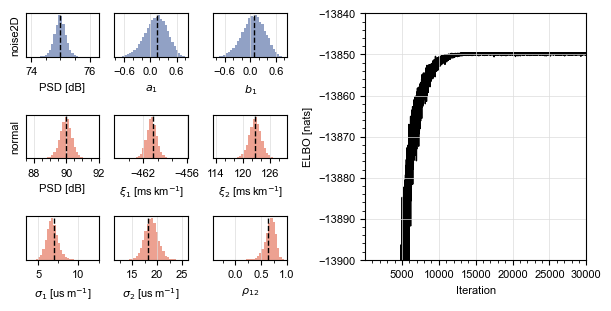

In [12]:
#__ Load true model for comparison __
m_true = synthetics['m_true']

#__ Create figure and axes __
fig = plt.figure(figsize=(6,3), facecolor='white', layout='constrained')
gs  = GridSpec(figure=fig, nrows=3, ncols=6)
axs = [fig.add_subplot(gs[:,3:])]
axs.extend([fig.add_subplot(gs[0,j]) for j in range(3)])
axs.extend([fig.add_subplot(gs[1,j]) for j in range(3)])
axs.extend([fig.add_subplot(gs[2,j]) for j in range(3)])

#__ Labels __
for ax, xlab, ylab in zip(axs,
    [r"Iteration",   r"PSD [dB]", r"$a_1$", r"$b_1$", r"PSD [dB]", r"$\xi_1$ [ms$\,$km$^{-1}$]", r"$\xi_2$ [ms$\,$km$^{-1}$]", r"$\sigma_1$ [us$\,$m$^{-1}$]", r"$\sigma_2$ [us$\,$m$^{-1}$]", r"$\rho_{12}$"],
    [r"ELBO [nats]", r"noise2D", None, None, r"normal", None, None, None, None, None]
):
    if (xlab is not None): ax.set_xlabel(xlab, fontsize=small)
    if (ylab is not None): ax.set_ylabel(ylab, fontsize=small)

#__ Ticks __
for ax, xlims, ylims, xticks, yticks in zip(axs,
    [(1,N_iterations), None, None, None, None, None, None, None, None, None],
    [(-13900,-13840), None, None, None, None, None, None, None, None, None],
    [(5000,1000), (2,0.5), (0.6,0.2), (0.6,0.2), (2,0.5), (6,2), (6,2), (5,2.5), (5,2.5), (0.5,0.25)],
    [(10,2), None, None, None, None, None, None, None, None, None]
):
    if (xlims is not None): ax.set_xlim(*xlims)
    if (ylims is not None): ax.set_ylim(*ylims)
    if (xticks is not None):
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xticks[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xticks[1]))
    else: ax.set_xticks([])
    if (yticks is not None):
        ax.yaxis.set_major_locator(ticker.MultipleLocator(yticks[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(yticks[1]))
    else: ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)

#__ Plot loss function __
axs[0].plot(1+np.arange(N_iterations), lnELBO, lw=1.0, c='k', zorder=1)

#__ Plot 'noise2D' parameter histograms __
scales = [1e0, 1e0, 1e0]
for mi, mi_true, ax, sc in zip(m.T[6:], m_true[6:], axs[1:4], scales):
    ax.hist(sc*mi, bins=30, color=theme[2], alpha=0.5, zorder=1)
    ax.axvline(sc*mi_true, lw=1.0, ls='--', color='k', zorder=2)

#__ Plot 'normal' parameter histograms __
scales = [1e0, 1e6, 1e6, 1e6, 1e6, 1e0]
for mi, mi_true, ax, sc in zip(m.T[:6], m_true[:6], axs[4:], scales):
    ax.hist(sc*mi, bins=30, color=theme[0], alpha=0.5, zorder=1)
    ax.axvline(sc*mi_true, lw=1.0, ls='--', color='k', zorder=2)

#__ Show figure __
fig.show()